In [9]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import SimpleITK as sitk

from src.models.swin_unetr_monai import SwinUNETR3D
from src.data.io_utils import read_tif_image, convert_image_to_array
from src.data.dataset_3class import create_datasets_3class

log_path = project_root / "outputs" / "swin_3class_slices40_focal_resume" / "logs" / "training.csv"
model_path = project_root / "outputs" / "swin_3class_slices40_focal_resume" / "checkpoints" / "best_model.pth"

df = pd.read_csv(log_path)
print(f"Logs chargés: {len(df)} époques")
print(f"Colonnes: {list(df.columns)}")

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Chargement du modèle...")
checkpoint = torch.load(model_path, map_location=device)

model = SwinUNETR3D(
    in_channels=1,
    out_channels=3,
    feature_size=48,
    drop_rate=0.0,
    attn_drop_rate=0.0,
    use_checkpoint=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print(f"✅ Modèle chargé sur {device}")
print(f"   Époque: {checkpoint.get('epoch', 'N/A')}")
print(f"   Meilleur score: {checkpoint.get('best_score', 'N/A')}")

Logs chargés: 50 époques
Colonnes: ['epoch', 'train_loss', 'train_dice', 'train_iou', 'val_loss', 'val_dice', 'val_iou', 'val_sensitivity', 'val_specificity', 'val_precision', 'val_accuracy', 'val_f1_score', 'val_dice_class0', 'val_dice_class1', 'val_dice_class2', 'epoch_time_seconds', 'train_time_seconds', 'val_time_seconds', 'gpu_memory_mb']
Chargement du modèle...
✅ Modèle chargé sur cuda
   Époque: 35
   Meilleur score: 0.6307844079309894


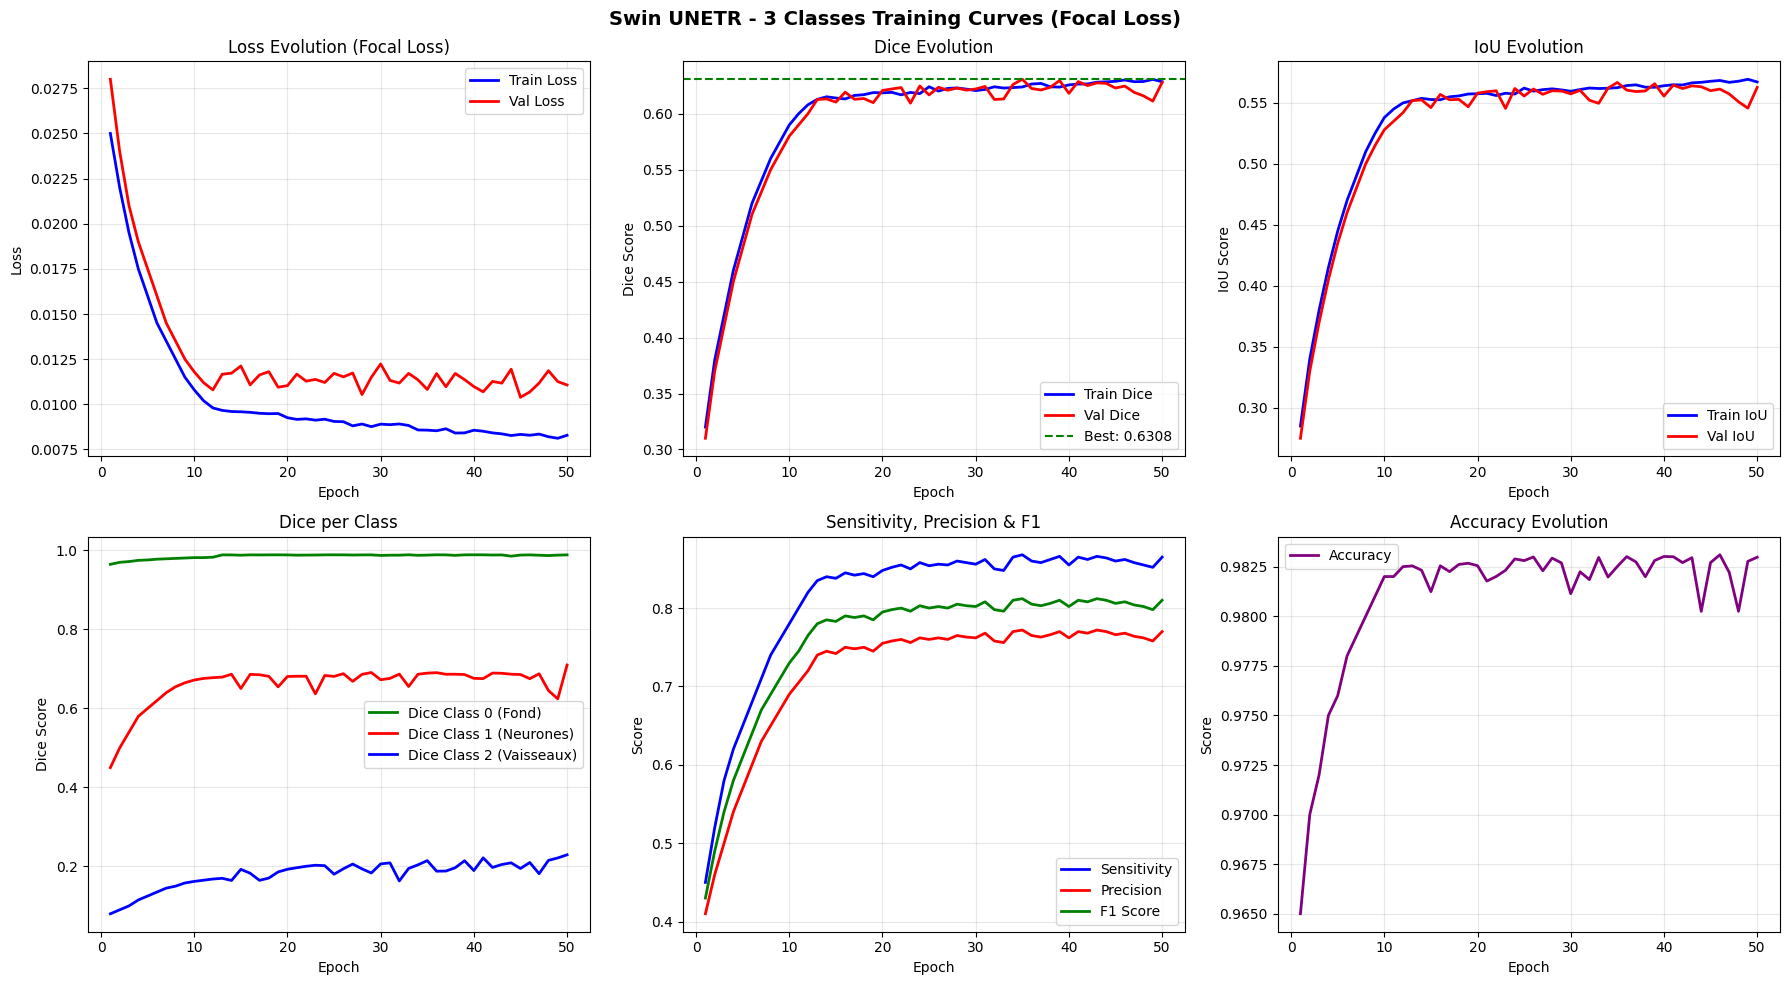

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

epochs = df['epoch'].values

axes[0, 0].plot(epochs, df['train_loss'], 'b-', label='Train Loss', linewidth=2)
axes[0, 0].plot(epochs, df['val_loss'], 'r-', label='Val Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Loss Evolution (Focal Loss)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(epochs, df['train_dice'], 'b-', label='Train Dice', linewidth=2)
axes[0, 1].plot(epochs, df['val_dice'], 'r-', label='Val Dice', linewidth=2)
axes[0, 1].axhline(y=df['val_dice'].max(), color='green', linestyle='--', label=f"Best: {df['val_dice'].max():.4f}")
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Dice Score')
axes[0, 1].set_title('Dice Evolution')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[0, 2].plot(epochs, df['train_iou'], 'b-', label='Train IoU', linewidth=2)
axes[0, 2].plot(epochs, df['val_iou'], 'r-', label='Val IoU', linewidth=2)
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('IoU Score')
axes[0, 2].set_title('IoU Evolution')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

axes[1, 0].plot(epochs, df['val_dice_class0'], 'g-', label='Dice Class 0 (Fond)', linewidth=2)
axes[1, 0].plot(epochs, df['val_dice_class1'], 'r-', label='Dice Class 1 (Neurones)', linewidth=2)
axes[1, 0].plot(epochs, df['val_dice_class2'], 'b-', label='Dice Class 2 (Vaisseaux)', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Dice Score')
axes[1, 0].set_title('Dice per Class')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(epochs, df['val_sensitivity'], 'b-', label='Sensitivity', linewidth=2)
axes[1, 1].plot(epochs, df['val_precision'], 'r-', label='Precision', linewidth=2)
axes[1, 1].plot(epochs, df['val_f1_score'], 'g-', label='F1 Score', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Score')
axes[1, 1].set_title('Sensitivity, Precision & F1')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].plot(epochs, df['val_accuracy'], 'purple', label='Accuracy', linewidth=2)
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Score')
axes[1, 2].set_title('Accuracy Evolution')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.suptitle('Swin UNETR - 3 Classes Training Curves (Focal Loss)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(project_root / "outputs" / "swin_3class_slices40_focal_resume" / "training_curves.png", dpi=150, bbox_inches='tight')
plt.show()

In [11]:
best_epoch = df.loc[df['val_dice'].idxmax()]
print("=" * 60)
print("STATISTIQUES RÉCAPITULATIVES - SWIN UNETR 3 CLASSES")
print("=" * 60)
print(f"Nombre d'époques: {len(df)}")
print(f"Meilleure époque: {int(best_epoch['epoch'])}")
print()
print("Meilleures métriques de validation:")
print(f"  Val Dice: {best_epoch['val_dice']:.4f}")
print(f"  Val IoU: {best_epoch['val_iou']:.4f}")
print(f"  Val Dice Class 0 (Fond): {best_epoch['val_dice_class0']:.4f}")
print(f"  Val Dice Class 1 (Neurones): {best_epoch['val_dice_class1']:.4f}")
print(f"  Val Dice Class 2 (Vaisseaux): {best_epoch['val_dice_class2']:.4f}")
print(f"  Val Sensitivity: {best_epoch['val_sensitivity']:.4f}")
print(f"  Val Precision: {best_epoch['val_precision']:.4f}")
print(f"  Val F1: {best_epoch['val_f1_score']:.4f}")
print(f"  Val Accuracy: {best_epoch['val_accuracy']:.4f}")
print()
print("Métriques finales (dernière époque):")
print(f"  Val Dice: {df['val_dice'].iloc[-1]:.4f}")
print(f"  Val Loss: {df['val_loss'].iloc[-1]:.4f}")
print(f"  Train Loss: {df['train_loss'].iloc[-1]:.4f}")
print()
print("Temps d'entraînement:")
print(f"  Total temps: {df['epoch_time_seconds'].sum()/3600:.2f} heures")
print(f"  Moyenne par époque: {df['epoch_time_seconds'].mean()/60:.2f} minutes")
print(f"  GPU Memory: {df['gpu_memory_mb'].max():.2f} MB")


STATISTIQUES RÉCAPITULATIVES - SWIN UNETR 3 CLASSES
Nombre d'époques: 50
Meilleure époque: 35

Meilleures métriques de validation:
  Val Dice: 0.6308
  Val IoU: 0.5668
  Val Dice Class 0 (Fond): 0.9883
  Val Dice Class 1 (Neurones): 0.6894
  Val Dice Class 2 (Vaisseaux): 0.2146
  Val Sensitivity: 0.8680
  Val Precision: 0.7720
  Val F1: 0.8120
  Val Accuracy: 0.9825

Métriques finales (dernière époque):
  Val Dice: 0.6279
  Val Loss: 0.0111
  Train Loss: 0.0083

Temps d'entraînement:
  Total temps: 64.82 heures
  Moyenne par époque: 77.78 minutes
  GPU Memory: 1749.00 MB


CREATING DATASETS (3 CLASSES)
Train dataset: 4945 samples
Val dataset: 618 samples
Test dataset: 619 samples

Nombre de patches de test: 619
Visualisation des prédictions sur le test set...


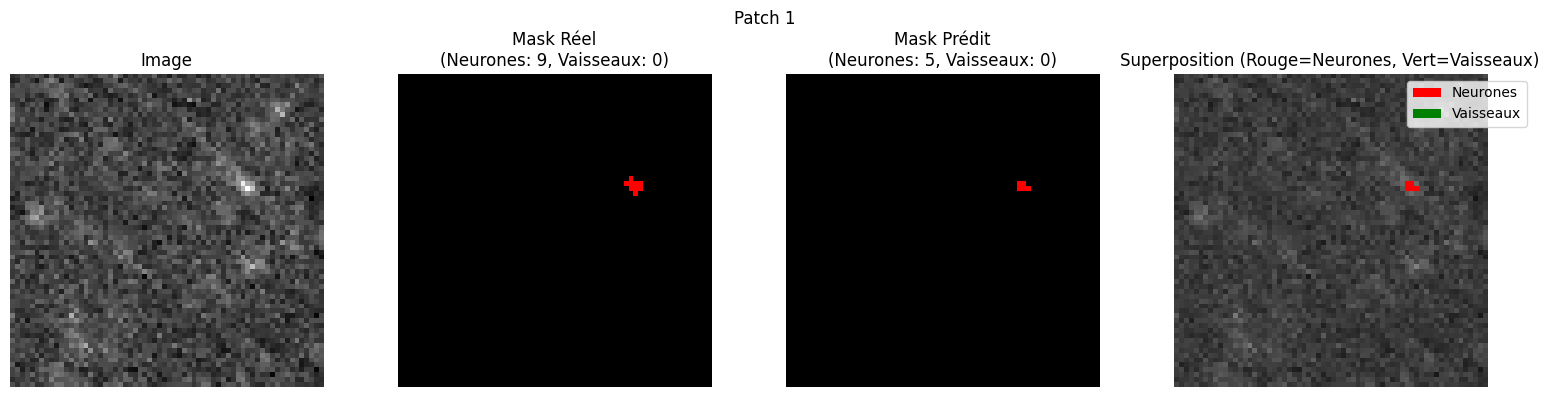

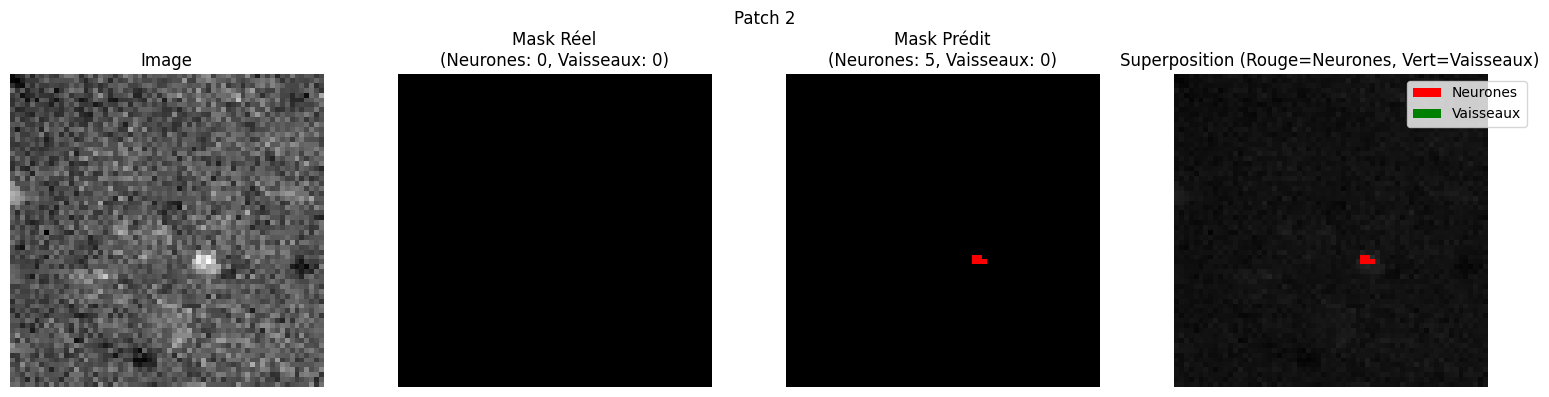

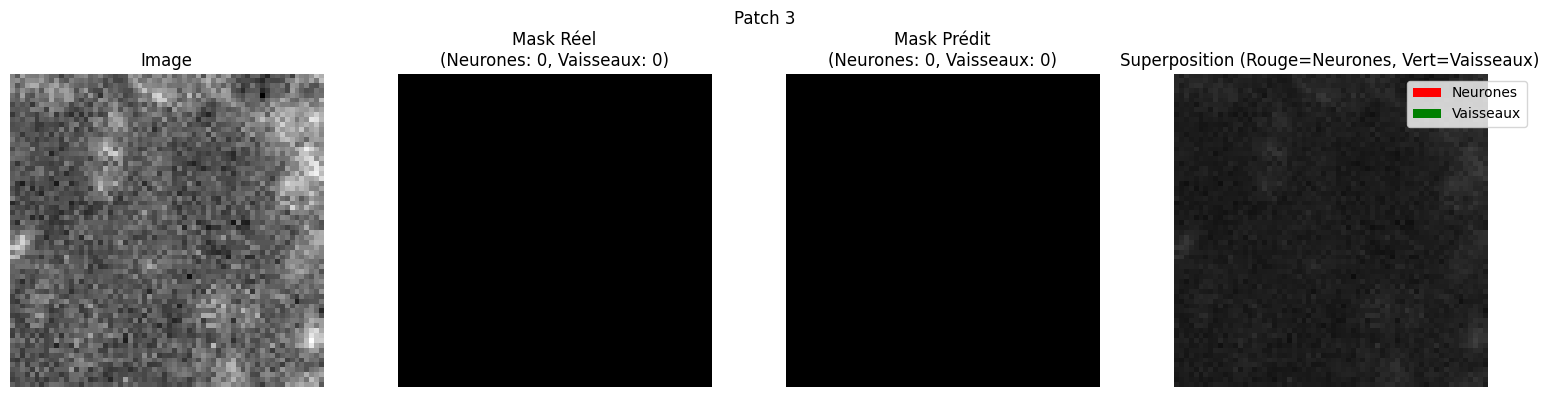

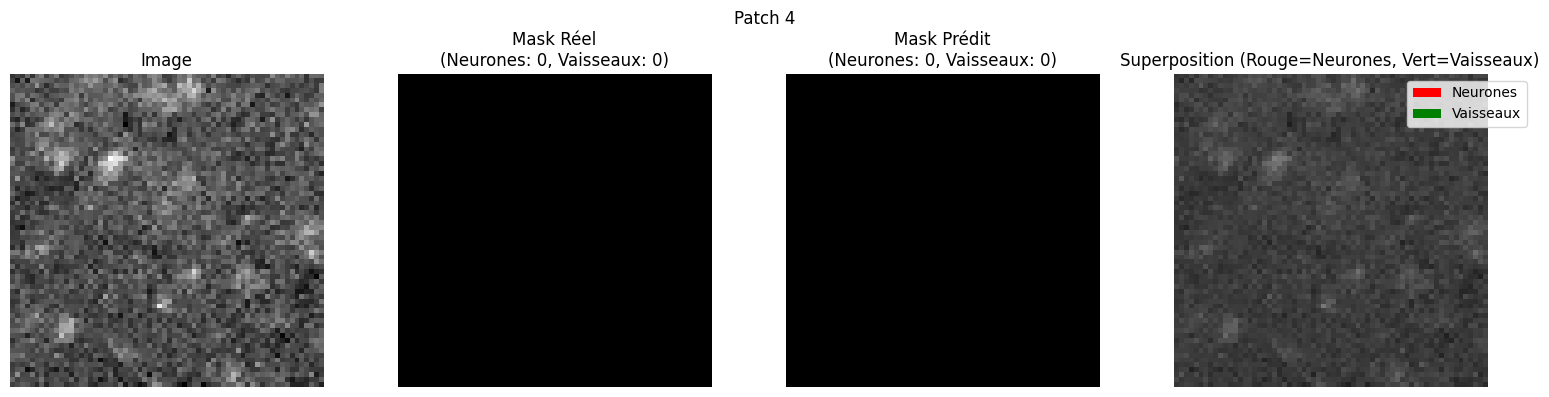

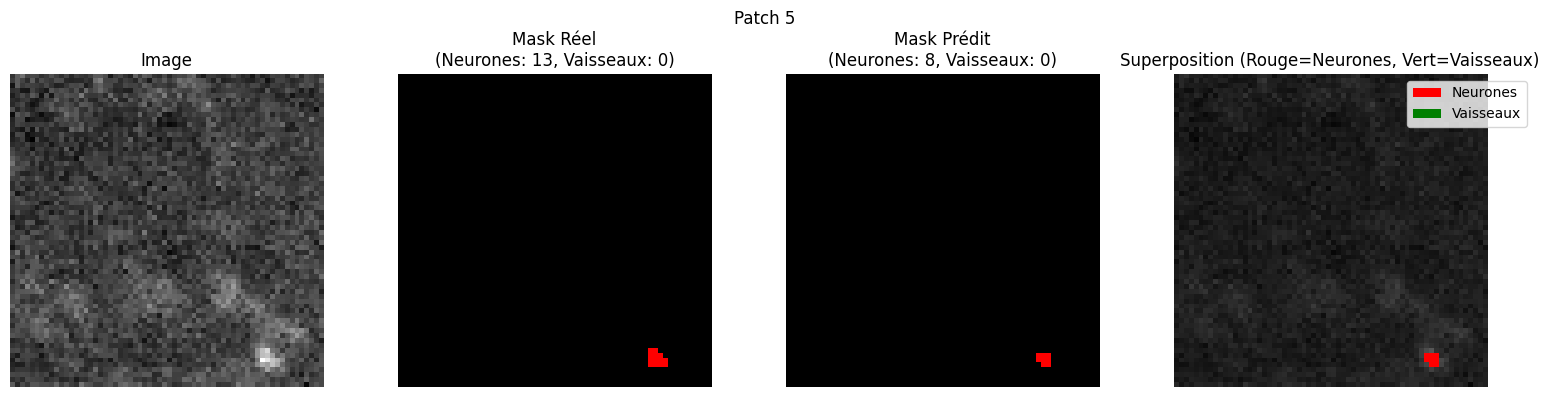

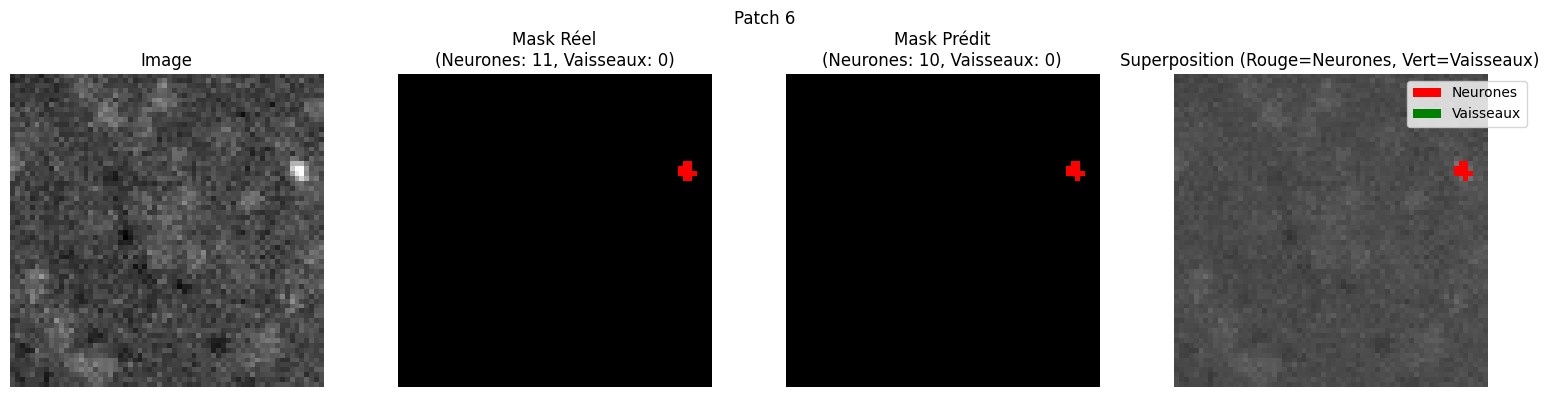

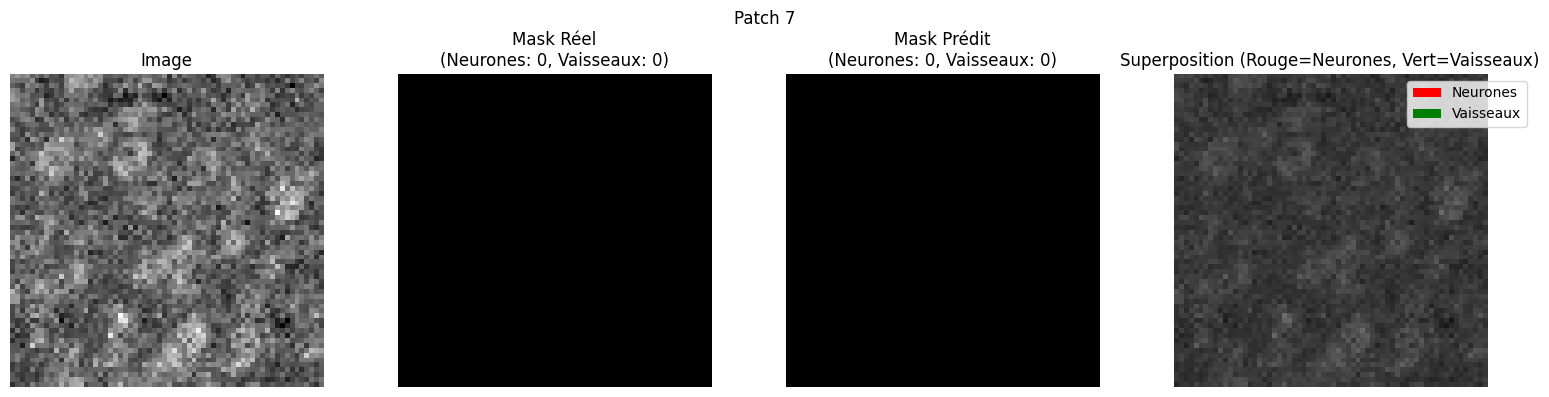

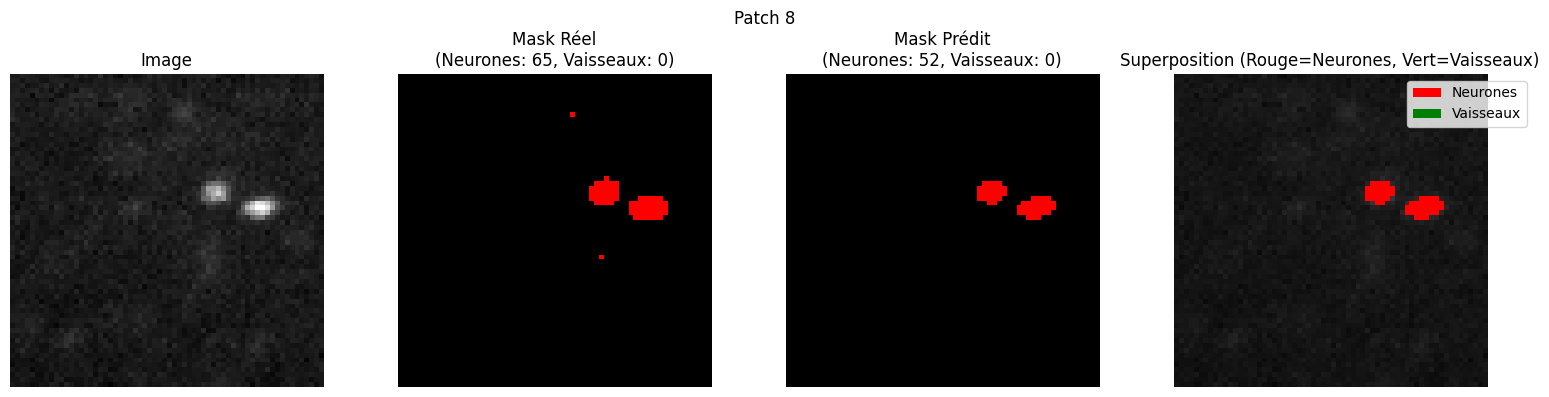

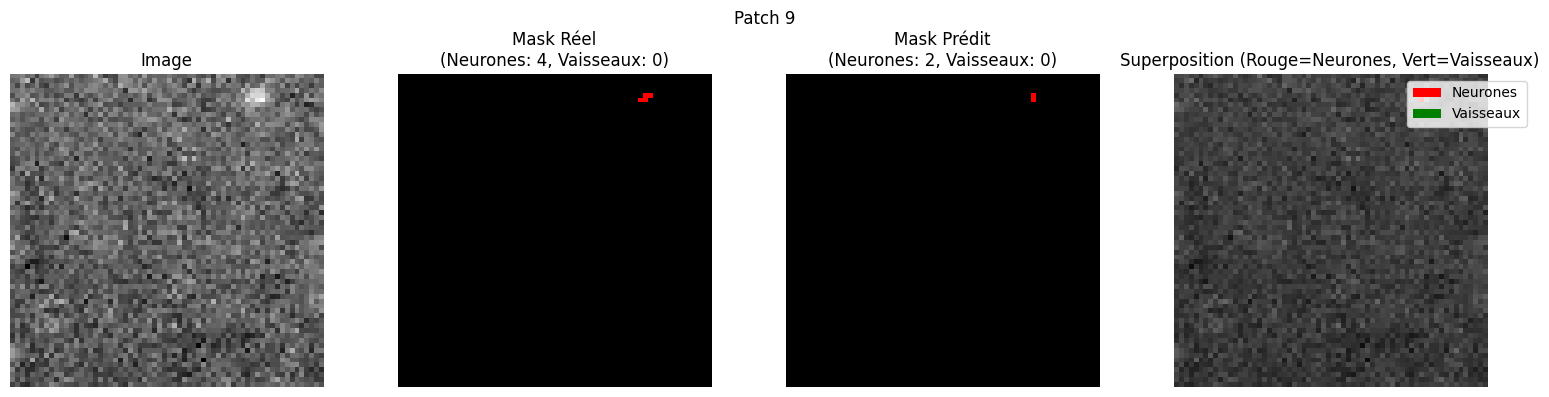

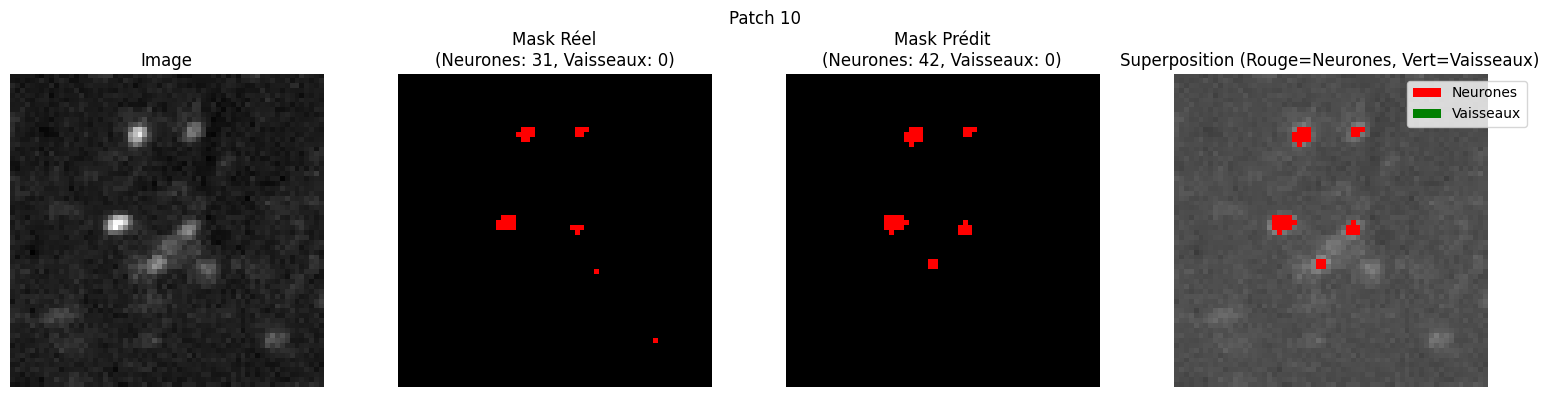

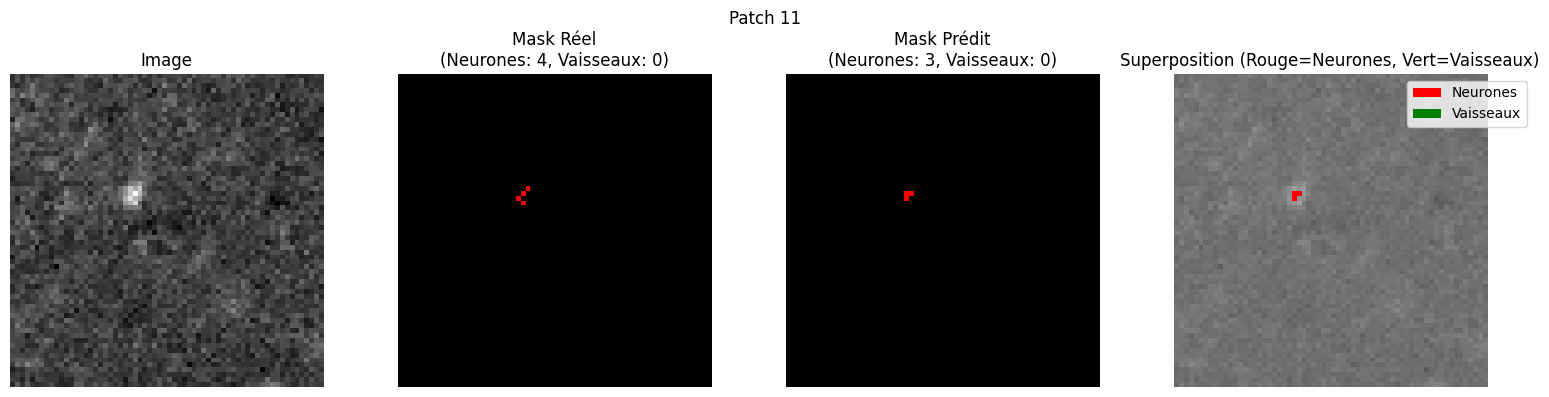

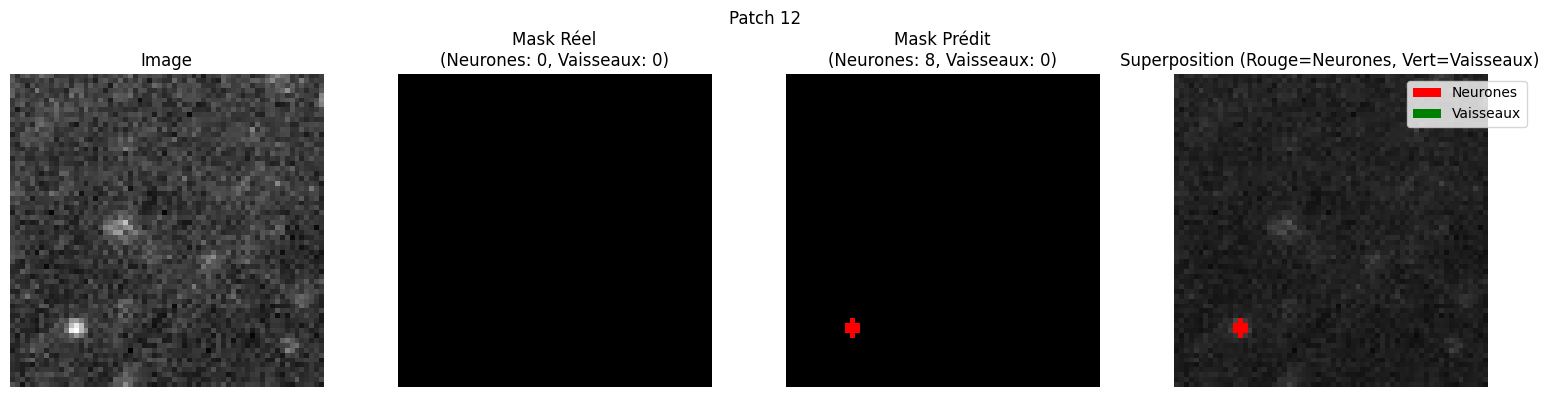

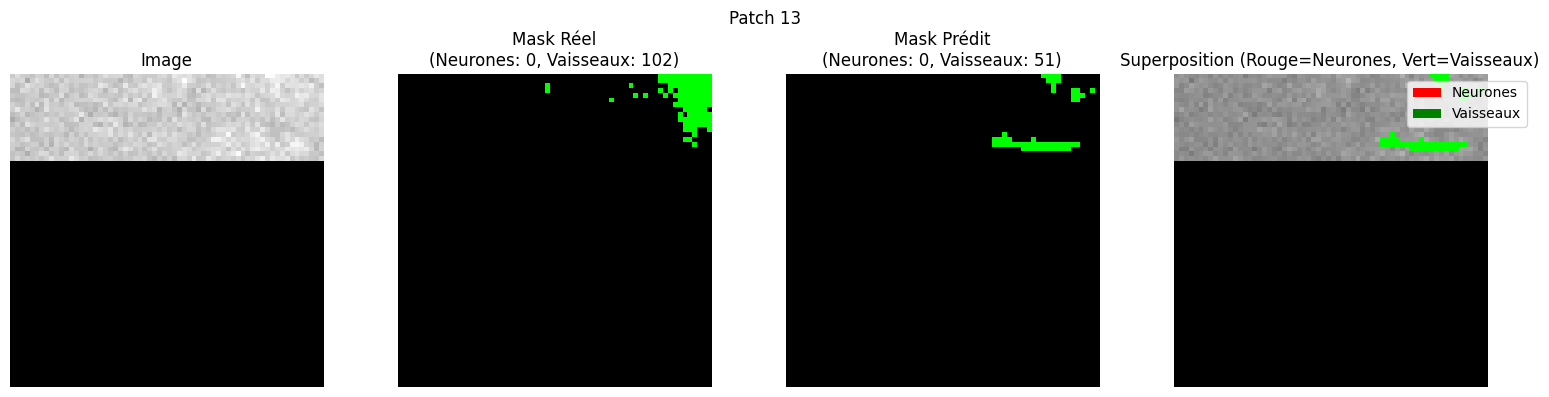

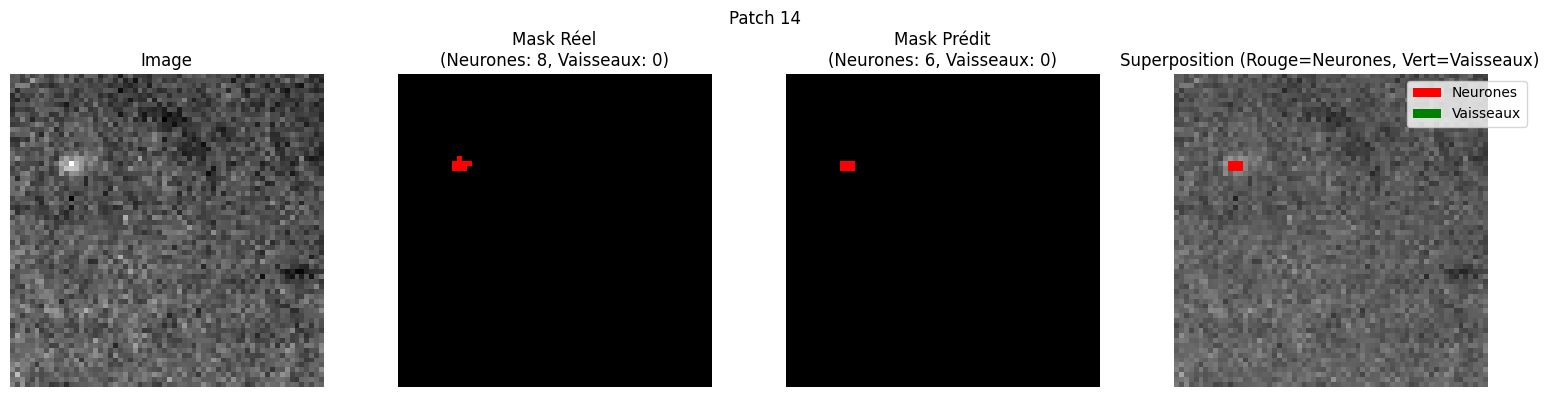

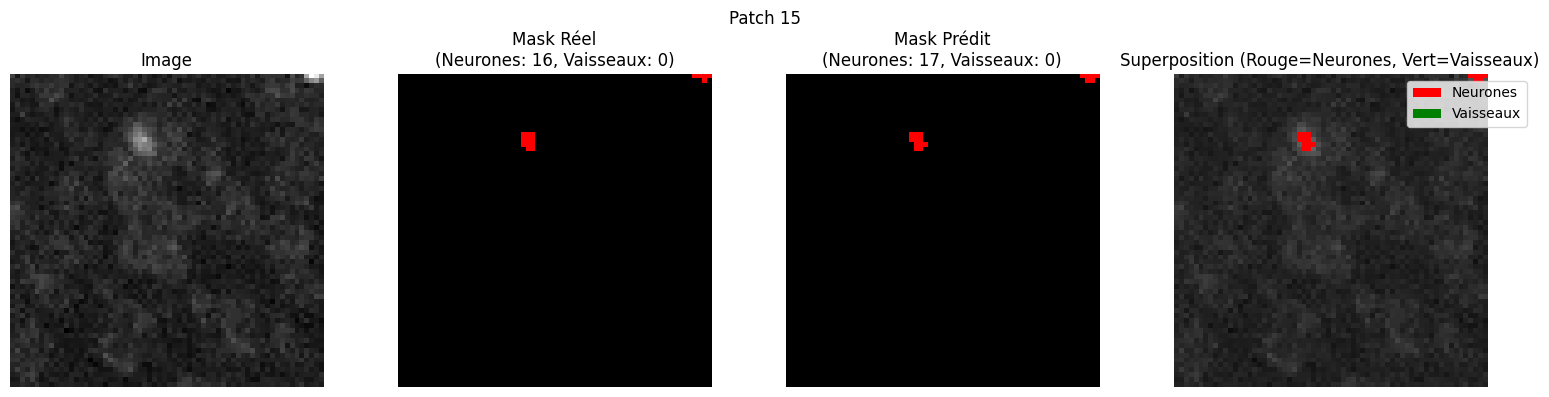

In [12]:
data_dir = Path("/mnt/x/donnees/pachs_64_3classes_filtered_slices")
splits_dir = data_dir / "splits"

_, _, test_loader = create_datasets_3class(
    data_dir=data_dir,
    splits_dir=splits_dir,
    batch_size=4,
    num_workers=0
)

print(f"Nombre de patches de test: {len(test_loader.dataset)}")

def predict_and_show_batch(loader, model, device, num_samples=15):
    model.eval()
    samples_shown = 0
    
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)
            
            preds = model(images)
            preds = torch.softmax(preds, dim=1)
            preds_class = torch.argmax(preds, dim=1).cpu().numpy()
            
            images_np = images.cpu().numpy()
            masks_np = masks.cpu().numpy()
            
            for i in range(images_np.shape[0]):
                if samples_shown >= num_samples:
                    return
                
                img = images_np[i, 0, ...]
                mask_true = masks_np[i, 0, ...]
                mask_pred = preds_class[i, ...]
                
                slice_idx = img.shape[0] // 2
                
                img_slice = img[slice_idx, :, :]
                if img_slice.max() > 1:
                    img_slice = img_slice / img_slice.max()
                
                mask_true_slice = mask_true[slice_idx, :, :]
                mask_pred_slice = mask_pred[slice_idx, :, :]
                
                rgb_true = np.zeros((mask_true_slice.shape[0], mask_true_slice.shape[1], 3), dtype=np.float32)
                rgb_true[mask_true_slice == 0] = [0, 0, 0]
                rgb_true[mask_true_slice == 1] = [1, 0, 0]
                rgb_true[mask_true_slice == 2] = [0, 1, 0]
                
                rgb_pred = np.zeros((mask_pred_slice.shape[0], mask_pred_slice.shape[1], 3), dtype=np.float32)
                rgb_pred[mask_pred_slice == 0] = [0, 0, 0]
                rgb_pred[mask_pred_slice == 1] = [1, 0, 0]
                rgb_pred[mask_pred_slice == 2] = [0, 1, 0]
                
                overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
                overlay[mask_pred_slice == 1, 0] = 1
                overlay[mask_pred_slice == 1, 1] = 0
                overlay[mask_pred_slice == 1, 2] = 0
                overlay[mask_pred_slice == 2, 0] = 0
                overlay[mask_pred_slice == 2, 1] = 1
                overlay[mask_pred_slice == 2, 2] = 0
                
                fig, axes = plt.subplots(1, 4, figsize=(16, 4))
                
                axes[0].imshow(img_slice, cmap='gray')
                axes[0].set_title('Image')
                axes[0].axis('off')
                
                axes[1].imshow(rgb_true)
                axes[1].set_title(f'Mask Réel\n(Neurones: {np.sum(mask_true_slice==1)}, Vaisseaux: {np.sum(mask_true_slice==2)})')
                axes[1].axis('off')
                
                axes[2].imshow(rgb_pred)
                axes[2].set_title(f'Mask Prédit\n(Neurones: {np.sum(mask_pred_slice==1)}, Vaisseaux: {np.sum(mask_pred_slice==2)})')
                axes[2].axis('off')
                
                axes[3].imshow(overlay)
                axes[3].set_title('Superposition (Rouge=Neurones, Vert=Vaisseaux)')
                axes[3].axis('off')
                
                from matplotlib.patches import Patch
                legend_elements = [
                    Patch(facecolor='red', label='Neurones'),
                    Patch(facecolor='green', label='Vaisseaux')
                ]
                axes[3].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
                
                plt.suptitle(f'Patch {samples_shown+1}')
                plt.tight_layout()
                plt.show()
                
                samples_shown += 1

print("Visualisation des prédictions sur le test set...")
predict_and_show_batch(test_loader, model, device, num_samples=15)


Calcul de la matrice de confusion sur 50 patches de test...


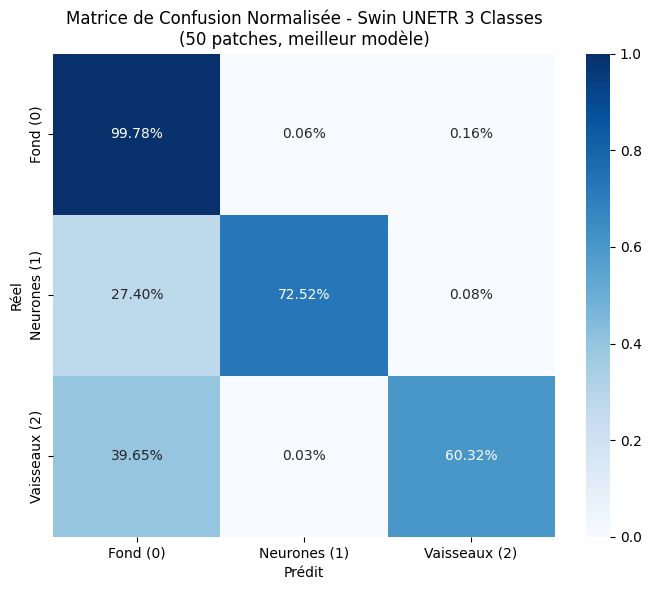

MATRICE DE CONFUSION - SWIN UNETR 3 CLASSES (50 patches)
Classe 0 (Fond) - Corrects: 12,908,318
Classe 1 (Neurones) - Corrects: 27,576
Classe 2 (Vaisseaux) - Corrects: 80,078

Erreurs de classification:
  Neurones classés en Fond: 10,421
  Neurones classés en Vaisseaux: 30
  Vaisseaux classés en Fond: 52,640
  Vaisseaux classés en Neurones: 43

Accuracy: 0.9930


In [13]:
# Matrice de confusion
from sklearn.metrics import confusion_matrix
import seaborn as sns

print("Calcul de la matrice de confusion sur 50 patches de test...")

all_true = []
all_pred = []
patches_count = 0

model.eval()

with torch.no_grad():
    for images, masks in test_loader:
        if patches_count >= 50:
            break
        
        images = images.to(device)
        masks = masks.to(device)
        
        preds = model(images)
        preds = torch.softmax(preds, dim=1)
        preds_class = torch.argmax(preds, dim=1).cpu().numpy()
        
        batch_size = images.shape[0]
        for i in range(batch_size):
            if patches_count >= 50:
                break
            all_true.extend(masks[i].cpu().numpy().flatten())
            all_pred.extend(preds_class[i].flatten())
            patches_count += 1

all_true = np.array(all_true)
all_pred = np.array(all_pred)

cm = confusion_matrix(all_true, all_pred, labels=[0, 1, 2])
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Fond (0)', 'Neurones (1)', 'Vaisseaux (2)'],
            yticklabels=['Fond (0)', 'Neurones (1)', 'Vaisseaux (2)'],
            ax=ax, vmin=0, vmax=1)
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
ax.set_title('Matrice de Confusion Normalisée - Swin UNETR 3 Classes\n(50 patches, meilleur modèle)')

plt.tight_layout()
plt.show()

print("=" * 50)
print("MATRICE DE CONFUSION - SWIN UNETR 3 CLASSES (50 patches)")
print("=" * 50)
print(f"Classe 0 (Fond) - Corrects: {cm[0,0]:,}")
print(f"Classe 1 (Neurones) - Corrects: {cm[1,1]:,}")
print(f"Classe 2 (Vaisseaux) - Corrects: {cm[2,2]:,}")
print()
print("Erreurs de classification:")
print(f"  Neurones classés en Fond: {cm[1,0]:,}")
print(f"  Neurones classés en Vaisseaux: {cm[1,2]:,}")
print(f"  Vaisseaux classés en Fond: {cm[2,0]:,}")
print(f"  Vaisseaux classés en Neurones: {cm[2,1]:,}")
print()
print(f"Accuracy: {(cm[0,0]+cm[1,1]+cm[2,2])/cm.sum():.4f}")

In [5]:
def pad_to_multiple(image, patch_size=64):
    current_shape = image.shape
    new_shape = []
    pads = []
    
    for dim in range(3):
        remainder = current_shape[dim] % patch_size
        if remainder == 0:
            new_shape.append(current_shape[dim])
            pads.append(0)
        else:
            pad = patch_size - remainder
            new_shape.append(current_shape[dim] + pad)
            pads.append(pad)
    
    new_shape = tuple(new_shape)
    pad_width = [(0, pads[0]), (0, pads[1]), (0, pads[2])]
    padded_image = np.pad(image, pad_width=pad_width, mode='constant', constant_values=0)
    
    return padded_image, pads, new_shape

def extract_patches_3d(image, patch_size=64):
    patches = []
    coords = []
    
    z_steps = image.shape[0] // patch_size
    y_steps = image.shape[1] // patch_size
    x_steps = image.shape[2] // patch_size
    
    for z in range(z_steps):
        for y in range(y_steps):
            for x in range(x_steps):
                z_start = z * patch_size
                y_start = y * patch_size
                x_start = x * patch_size
                
                patch = image[
                    z_start:z_start + patch_size,
                    y_start:y_start + patch_size,
                    x_start:x_start + patch_size
                ]
                patches.append(patch)
                coords.append((z_start, y_start, x_start))
    
    return patches, coords

def reconstruct_from_patches(patches, coords, original_shape, patch_size=64):
    reconstructed = np.zeros(original_shape, dtype=np.float32)
    weights = np.zeros(original_shape, dtype=np.float32)
    
    for patch, (z_start, y_start, x_start) in zip(patches, coords):
        reconstructed[
            z_start:z_start + patch_size,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ] += patch
        weights[
            z_start:z_start + patch_size,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ] += 1
    
    weights[weights == 0] = 1
    reconstructed = reconstructed / weights
    
    return reconstructed

def save_array(array, file_path):
    sitk_image = sitk.GetImageFromArray(array.astype(np.uint8))
    sitk.WriteImage(sitk_image, str(file_path))


In [6]:
image_path = Path("/mnt/x/donnees/images_test/images/image.tif")
mask_path = Path("/mnt/x/donnees/images_test/masks/mask.tif")
output_path = Path("/mnt/x/donnees/images_test/swint3_classes_prediction/mask_swin_3_classes_predit.tif")
output_path.parent.mkdir(parents=True, exist_ok=True)

print("Chargement de l'image brute...")
image_sitk = read_tif_image(str(image_path))
image = convert_image_to_array(image_sitk)
mask_sitk = read_tif_image(str(mask_path))
mask_true = convert_image_to_array(mask_sitk)

print(f"Image shape: {image.shape}")
print(f"Mask shape: {mask_true.shape}")

PATCH_SIZE = 64
padded_image, pads, padded_shape = pad_to_multiple(image, PATCH_SIZE)
print(f"Image originale: {image.shape}")
print(f"Image paddée: {padded_shape}")

patches, coords = extract_patches_3d(padded_image, PATCH_SIZE)
print(f"Nombre de patches: {len(patches)}")

print("Prédiction en cours...")
predictions = []

with torch.no_grad():
    for patch in tqdm(patches, desc="Patches"):
        patch_norm = patch.astype(np.float32)
        min_val = patch_norm.min()
        max_val = patch_norm.max()
        if max_val - min_val > 0:
            patch_norm = (patch_norm - min_val) / (max_val - min_val)
        else:
            patch_norm = np.zeros_like(patch_norm)
        
        patch_tensor = torch.from_numpy(patch_norm).float()
        patch_tensor = patch_tensor.unsqueeze(0).unsqueeze(0).to(device)
        
        pred = model(patch_tensor)
        pred = torch.softmax(pred, dim=1)
        pred = pred.cpu().numpy().squeeze()
        pred_class = np.argmax(pred, axis=0).astype(np.float32)
        predictions.append(pred_class)

reconstructed = reconstruct_from_patches(predictions, coords, padded_shape, PATCH_SIZE)

if pads[0] > 0:
    reconstructed = reconstructed[:-pads[0], :, :]
if pads[1] > 0:
    reconstructed = reconstructed[:, :-pads[1], :]
if pads[2] > 0:
    reconstructed = reconstructed[:, :, :-pads[2]]

print(f"Image reconstruite: {reconstructed.shape}")
save_array(reconstructed, output_path)
print(f"Mask sauvegardé: {output_path}")


Chargement de l'image brute...
Image shape: (299, 634, 580)
Mask shape: (299, 634, 580)
Image originale: (299, 634, 580)
Image paddée: (320, 640, 640)
Nombre de patches: 500
Prédiction en cours...


Patches: 100%|███████████████████████████████████████████████████████████| 500/500 [02:06<00:00,  3.94it/s]


Image reconstruite: (299, 634, 580)
Mask sauvegardé: /mnt/x/donnees/images_test/swint3_classes_prediction/mask_swin_3_classes_predit.tif


Visualisation de l'image brute et du mask prédit...


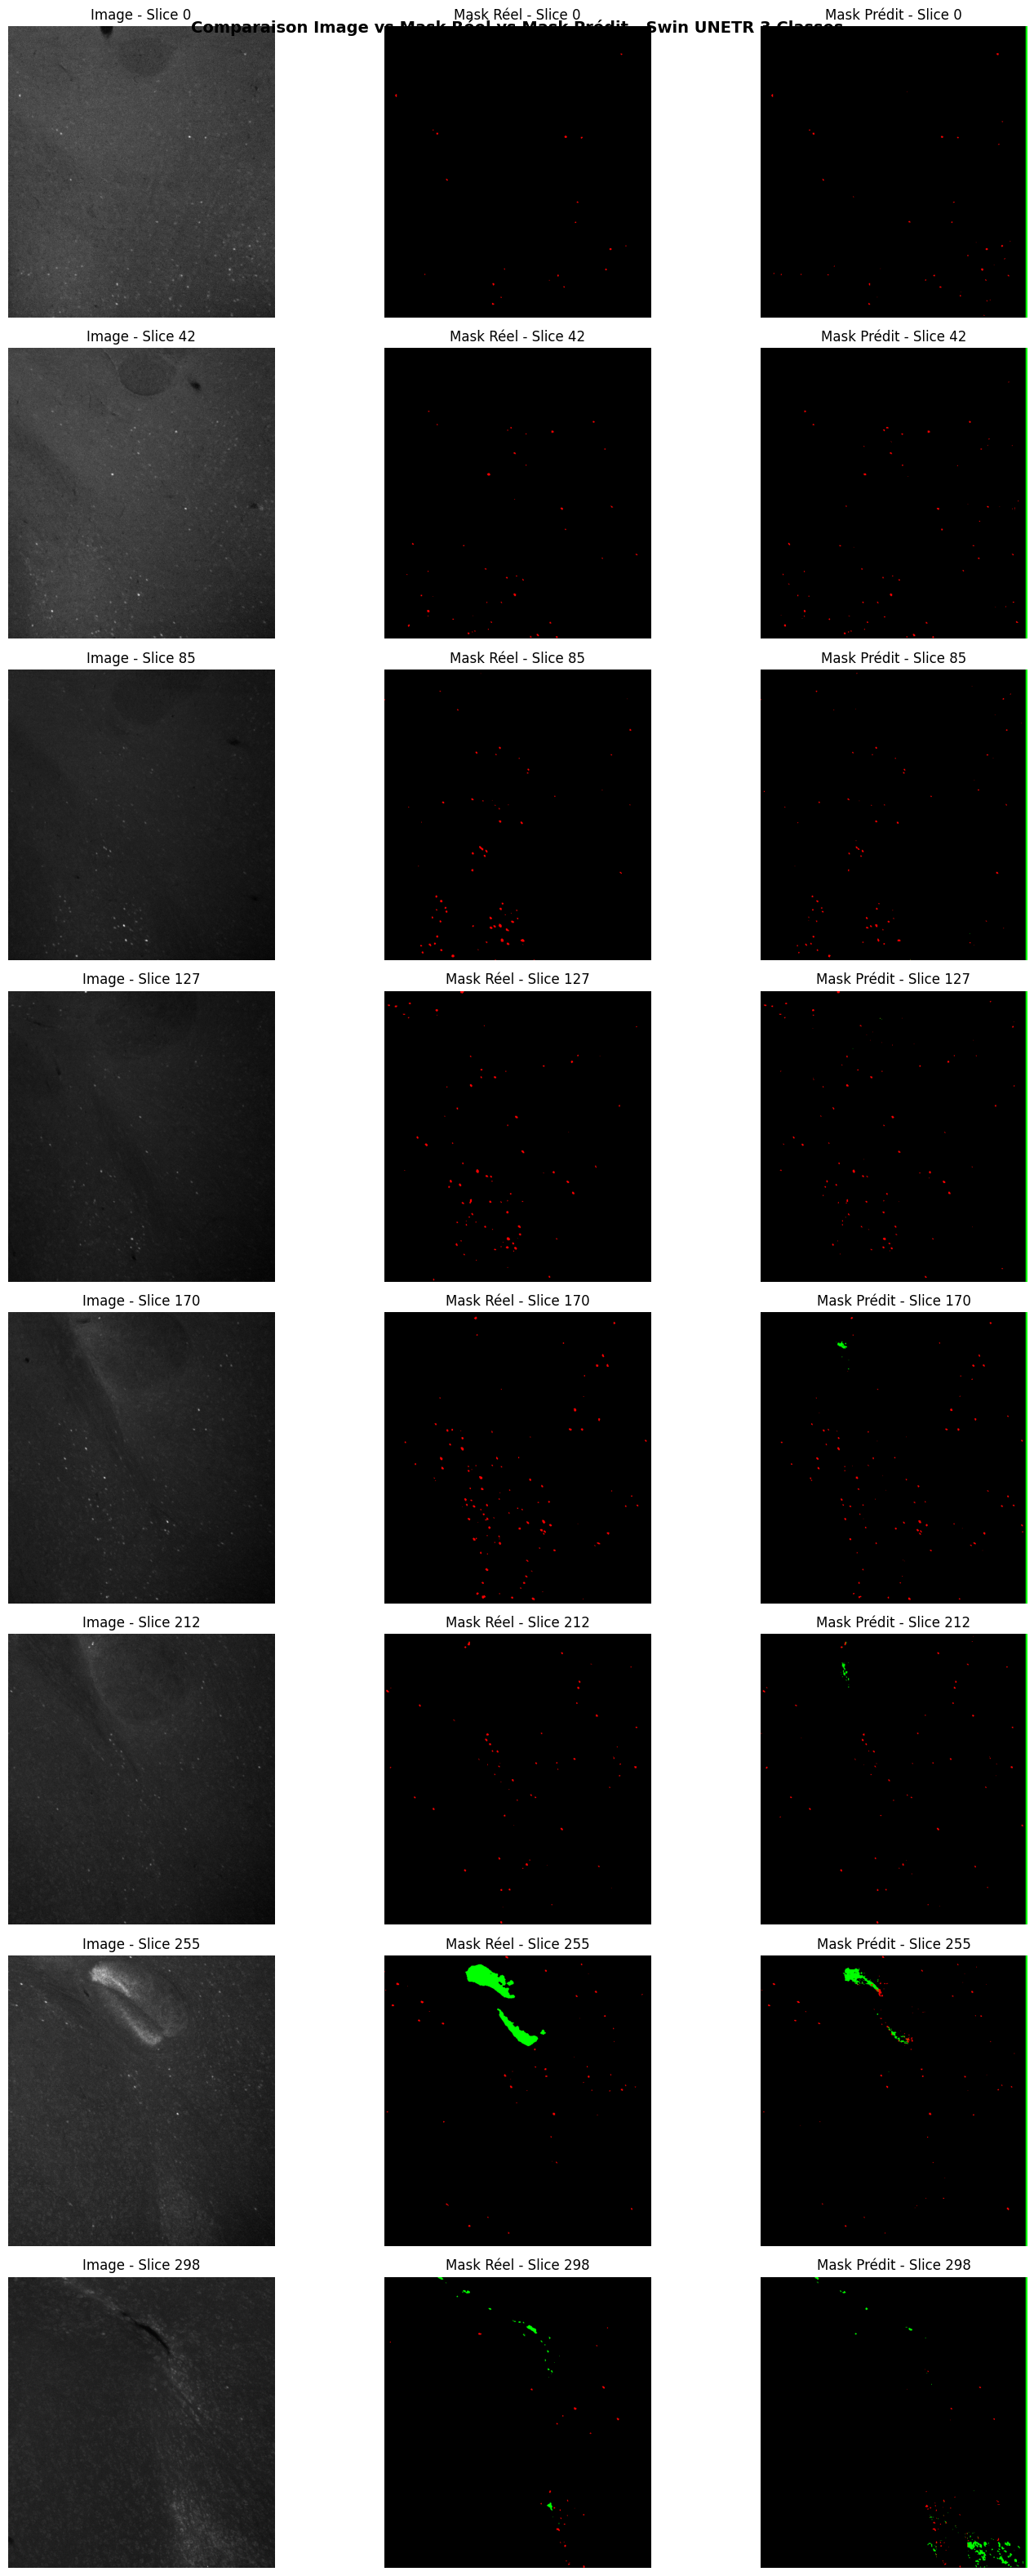

In [7]:
def visualize_slices(image, mask_true, mask_pred, num_slices=6):
    total_z = image.shape[0]
    slice_indices = np.linspace(0, total_z - 1, num_slices, dtype=int)
    
    fig, axes = plt.subplots(num_slices, 3, figsize=(15, 4*num_slices))
    
    for i, z_idx in enumerate(slice_indices):
        img_slice = image[z_idx, :, :]
        if img_slice.max() > 1:
            img_slice = img_slice / img_slice.max()
        
        rgb_true = np.zeros((mask_true[z_idx, :, :].shape[0], mask_true[z_idx, :, :].shape[1], 3), dtype=np.float32)
        rgb_true[mask_true[z_idx, :, :] == 0] = [0, 0, 0]
        rgb_true[mask_true[z_idx, :, :] == 1] = [1, 0, 0]
        rgb_true[mask_true[z_idx, :, :] == 2] = [0, 1, 0]
        
        rgb_pred = np.zeros((mask_pred[z_idx, :, :].shape[0], mask_pred[z_idx, :, :].shape[1], 3), dtype=np.float32)
        rgb_pred[mask_pred[z_idx, :, :] == 0] = [0, 0, 0]
        rgb_pred[mask_pred[z_idx, :, :] == 1] = [1, 0, 0]
        rgb_pred[mask_pred[z_idx, :, :] == 2] = [0, 1, 0]
        
        axes[i, 0].imshow(img_slice, cmap='gray')
        axes[i, 0].set_title(f'Image - Slice {z_idx}')
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(rgb_true)
        axes[i, 1].set_title(f'Mask Réel - Slice {z_idx}')
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(rgb_pred)
        axes[i, 2].set_title(f'Mask Prédit - Slice {z_idx}')
        axes[i, 2].axis('off')
    
    plt.suptitle('Comparaison Image vs Mask Réel vs Mask Prédit - Swin UNETR 3 Classes', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print("Visualisation de l'image brute et du mask prédit...")
visualize_slices(image, mask_true, reconstructed, num_slices=8)


In [8]:
pred_neurons = (reconstructed == 1).sum()
pred_vessels = (reconstructed == 2).sum()
true_neurons = (mask_true == 1).sum()
true_vessels = (mask_true == 2).sum()

print("=" * 60)
print("STATISTIQUES DE L'IMAGE PRÉDITE - SWIN UNETR 3 CLASSES")
print("=" * 60)
print(f"Image shape: {image.shape}")
print(f"Mask shape: {reconstructed.shape}")
print()
print(f"Neurones réels: {true_neurons}")
print(f"Neurones prédits: {pred_neurons}")
print(f"Ratio neurones: {pred_neurons / true_neurons if true_neurons > 0 else 0:.2f}")
print()
print(f"Vaisseaux réels: {true_vessels}")
print(f"Vaisseaux prédits: {pred_vessels}")
print(f"Ratio vaisseaux: {pred_vessels / true_vessels if true_vessels > 0 else 0:.2f}")
print()
print(f"Padding ajouté: {pads}")
print(f"Patches créés: {len(patches)}")
print(f"Mask sauvegardé: {output_path}")
print("=" * 60)

STATISTIQUES DE L'IMAGE PRÉDITE - SWIN UNETR 3 CLASSES
Image shape: (299, 634, 580)
Mask shape: (299, 634, 580)

Neurones réels: 222071
Neurones prédits: 171201
Ratio neurones: 0.77

Vaisseaux réels: 186765
Vaisseaux prédits: 898972
Ratio vaisseaux: 4.81

Padding ajouté: [21, 6, 60]
Patches créés: 500
Mask sauvegardé: /mnt/x/donnees/images_test/swint3_classes_prediction/mask_swin_3_classes_predit.tif
